# Разработка A/B-теста и анализ результатов

- Автор: Новаковский Дмитрий
- Дата: 16.10.2026

В развлекательном приложении с «бесконечной» лентой команда разработала новый алгоритм рекомендаций. Задача — рассчитать параметры A/B-теста, проверить корректность его проведения и оценить, растёт ли доля успешных первых сессий (4 и более просмотренных страниц).

## Данные

Сессии пользователей приложения: исторические данные (15.08–23.09.2025), данные первого дня теста (14.10.2025) и полные данные теста (14.10–02.11.2025). Поля: идентификаторы пользователя и сессии, даты сессии и установки, номер сессии, флаг регистрации, число просмотренных страниц, регион, устройство, тестовая группа. Учебный датасет Яндекс Практикума, в репозиторий не включён.

### 1. Работа с историческими данными (EDA)

#### 1.1. Загрузка исторических данных

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from math import ceil
from scipy.stats import chisquare
from statsmodels.stats.power import NormalIndPower
from statsmodels.stats.proportion import proportion_effectsize, proportions_ztest

In [2]:
sessions_history = pd.read_csv(
    '/datasets/sessions_project_history.csv',
    parse_dates=['session_date', 'session_start_ts', 'install_date']
)
sessions_history.head()

,user_id,session_id,session_date,session_start_ts,install_date,session_number,registration_flag,page_counter,region,device
0,E302123B7000BFE4,F9AF61A0C2023832,2025-08-15,2025-08-15 17:47:35,2025-08-15,1,0,3,CIS,iPhone
1,2530F72E221829FB,85003A206CBDAC6F,2025-08-15,2025-08-15 16:42:14,2025-08-15,1,0,4,MENA,Android
2,876E020A4FC512F5,3677423E49D72DEE,2025-08-15,2025-08-15 12:30:00,2025-08-15,1,0,4,EU,PC
3,2640B349E1D81584,956B45F5915CA225,2025-08-15,2025-08-15 15:31:31,2025-08-15,1,0,4,CIS,Android
4,94E1CBFAEF1F5EE9,83BF0DA35F9F1F40,2025-08-15,2025-08-15 21:33:53,2025-08-15,1,0,3,CIS,Android


#### 1.2. Знакомство с данными

In [3]:
sessions_per_user = (
    sessions_history.groupby('user_id')['session_id']
    .nunique()
    .sort_values(ascending=False)
)
print(sessions_per_user.head())

# все данные пользователя с наибольшим числом сессий в хронологическом порядке
top_user = sessions_per_user.index[0]
sessions_history[sessions_history['user_id'] == top_user].sort_values('session_start_ts')

user_id
10E0DEFC1ABDBBE0    10
6A73CB5566BB494D    10
8A60431A825D035B     9
D11541BAC141FB94     9
5BCFE7C4DCC148E9     9
Name: session_id, dtype: int64


,user_id,session_id,session_date,session_start_ts,install_date,session_number,registration_flag,page_counter,region,device
115558,10E0DEFC1ABDBBE0,B8F0423BBFFCF5DC,2025-08-14,2025-08-14 13:57:39,2025-08-14,1,0,4,CIS,Android
191751,10E0DEFC1ABDBBE0,87CA2FA549473837,2025-08-15,2025-08-15 16:42:10,2025-08-14,2,0,3,CIS,Android
239370,10E0DEFC1ABDBBE0,4ADD8011DCDCE318,2025-08-16,2025-08-16 19:53:21,2025-08-14,3,0,3,CIS,Android
274629,10E0DEFC1ABDBBE0,DF0FD0E09BF1F3D7,2025-08-17,2025-08-17 15:03:43,2025-08-14,4,0,1,CIS,Android
302501,10E0DEFC1ABDBBE0,3C221774B4DE6885,2025-08-18,2025-08-18 17:29:14,2025-08-14,5,0,4,CIS,Android
325557,10E0DEFC1ABDBBE0,031BD7A67048105B,2025-08-19,2025-08-19 13:23:55,2025-08-14,6,0,2,CIS,Android
345336,10E0DEFC1ABDBBE0,FF4315CF4AD4B100,2025-08-20,2025-08-20 19:31:54,2025-08-14,7,0,2,CIS,Android
377532,10E0DEFC1ABDBBE0,4045FEA0747203B4,2025-08-22,2025-08-22 17:54:13,2025-08-14,8,0,2,CIS,Android
403538,10E0DEFC1ABDBBE0,344B086C421C7F37,2025-08-24,2025-08-24 14:46:13,2025-08-14,9,0,2,CIS,Android
414743,10E0DEFC1ABDBBE0,054F20BA371E4C9D,2025-08-25,2025-08-25 18:36:41,2025-08-14,10,0,3,CIS,Android


#### 1.3. Анализ числа регистраций

In [4]:
daily = (
    sessions_history
    .groupby('session_date')
    .agg(total_users=('user_id', 'nunique'),
         registered_users=('registration_flag', 'sum'))
    .reset_index()
)
daily['session_date'] = pd.to_datetime(daily['session_date'])
daily['registered_share'] = daily['registered_users'] / daily['total_users']
daily.head()

,session_date,total_users,registered_users,registered_share
0,2025-08-11,3919,169,0.043123
1,2025-08-12,6056,336,0.055482
2,2025-08-13,8489,464,0.054659
3,2025-08-14,10321,625,0.060556
4,2025-08-15,14065,840,0.059723


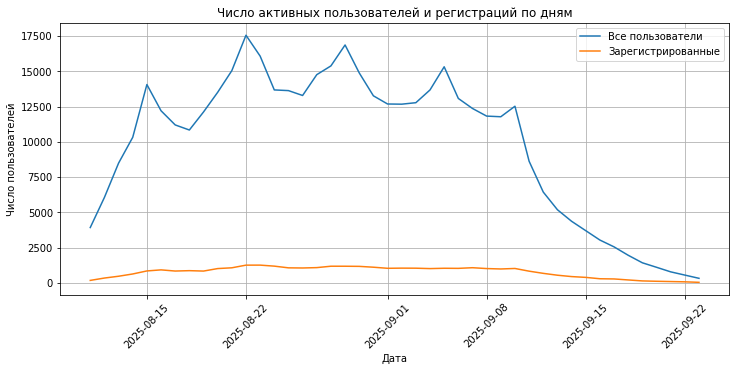

In [5]:
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(daily['session_date'], daily['total_users'], label='Все пользователи')
ax.plot(daily['session_date'], daily['registered_users'], label='Зарегистрированные')
ax.set_title('Число активных пользователей и регистраций по дням')
ax.set_xlabel('Дата')
ax.set_ylabel('Число пользователей')
ax.grid(True)
ax.legend()
plt.xticks(rotation=45)
plt.show()

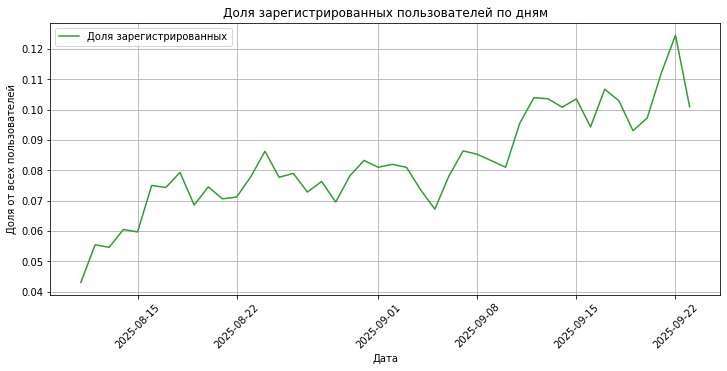

In [6]:
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(daily['session_date'], daily['registered_share'], color='tab:green', label='Доля зарегистрированных')
ax.set_title('Доля зарегистрированных пользователей по дням')
ax.set_xlabel('Дата')
ax.set_ylabel('Доля от всех пользователей')
ax.grid(True)
ax.legend()
plt.xticks(rotation=45)
plt.show()

#### 1.4. Анализ числа просмотренных страниц

In [7]:
first_sessions = sessions_history[sessions_history['session_number'] == 1]
pages_counts = first_sessions['page_counter'].value_counts().sort_index()
pages_counts

1     8978
2    32494
3    50939
4    32739
5     8075
6      777
7       37
Name: page_counter, dtype: int64

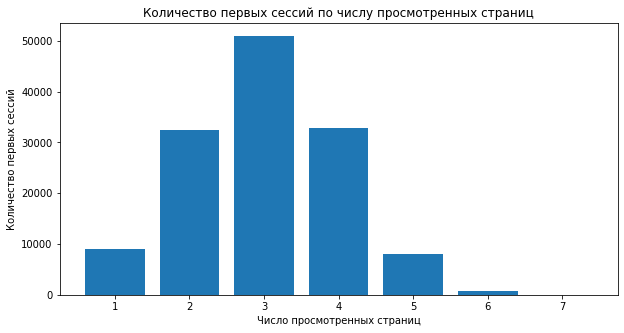

In [8]:
fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(pages_counts.index, pages_counts.values)
ax.set_title('Количество первых сессий по числу просмотренных страниц')
ax.set_xlabel('Число просмотренных страниц')
ax.set_ylabel('Количество первых сессий')
ax.set_xticks(pages_counts.index)
plt.show()

Распределение первых сессий по числу просмотренных страниц близко к колоколообразному с пиком на 3 страницах:

| Страниц | 1 | 2 | 3 | 4 | 5 | 6 | 7 |
|---|---|---|---|---|---|---|---|
| Первых сессий | 8 978 | 32 494 | 50 939 | 32 739 | 8 075 | 777 | 37 |

Всего 134 039 первых сессий. Самая частая — сессия с 3 страницами (около 38%), на 2 страницы приходится 24%, на 1 страницу 7%. Сессии с 4 и более страницами (пороговое значение для успешной сессии) составляют 41628, то есть около 31% всех первых сессий. Больше 6 страниц в первой сессии просматривают единицы.

#### 1.5. Доля пользователей, просмотревших более четырёх страниц

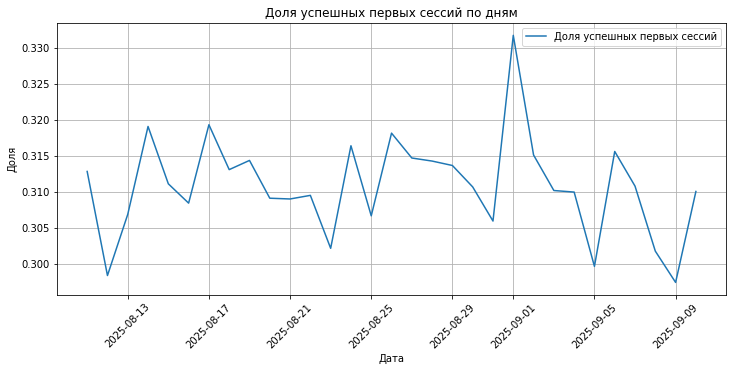

Средняя доля успешных первых сессий: 0.3108


In [9]:
sessions_history['good_session'] = (sessions_history['page_counter'] >= 4).astype(int)

good_share_daily = (
    sessions_history[sessions_history['session_number'] == 1]
    .groupby('session_date')['good_session']
    .mean()
    .reset_index()
)
good_share_daily['session_date'] = pd.to_datetime(good_share_daily['session_date'])

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(good_share_daily['session_date'], good_share_daily['good_session'], label='Доля успешных первых сессий')
ax.set_title('Доля успешных первых сессий по дням')
ax.set_xlabel('Дата')
ax.set_ylabel('Доля')
ax.grid(True)
ax.legend()
plt.xticks(rotation=45)
plt.show()

print('Средняя доля успешных первых сессий:', round(good_share_daily['good_session'].mean(), 4))

Дневная доля успешных первых сессий колеблется в узком диапазоне 30–33%, средняя за период  31,1%. Явного тренда нет. Единственный заметный всплеск (33%) приходится на 1 сентября. Это важно для теста: базовое значение метрики стабильно (0,31), поэтому его можно использовать как точку отсчёта и сравнивать группы. Базовая доля p = 0,3, взятая в расчёт выборки, близка к реальной.

**Промежуточный вывод по EDA**

- **Период и аудитория.** В исторических данных активная аудитория быстро растёт с 3,9 тыс. пользователей в день (11 августа) до пика около 17,5 тыс. (22 августа), до 10 сентября держится на уровне 12–15 тыс., затем резко падает: после 10 сентября новых установок нет, и аудитория выгорает. Среднее число уникальных пользователей в день — около 9900.
- **Регистрации.** Число регистраций в день выросло с 170 до 1,2 тыс. и держалось на уровне 1–1,2 тыс. до 10 сентября. Доля зарегистрированных выросла с 4,3% до 8% к концу августа и до 10% в середине сентября. Значения в последние дни ненадёжны из-за малой аудитории.
- **Просмотры страниц.** Всего 134039 первых сессий. Распределение числа страниц колоколообразное с пиком на 3 страницах (около 38% первых сессий). Сессии с 4 и более страницами составляют около 31% (41628).
- **Целевая метрика.** Доля успешных первых сессий в течение периода стабильна: колеблется в диапазоне 30–33%, средняя 31,1%, явного тренда нет. Это надёжная точка отсчёта для теста, а базовая доля 0,3 в расчёте выборки близка к реальной.
- **Что это значит для теста.** Метрика стабильна, поэтому изменение доли в группе B можно сравнивать с контрольной группой A. Данные годятся для расчёта размера выборки и длительности теста.

### 2. Подготовка к тесту

#### 2.1. Расчёт размера выборки

In [10]:
alpha = 0.05
beta = 0.2
power = 1 - beta
p = 0.3
mde = p * 0.03
effect_size = proportion_effectsize(p, p + mde)

power_analysis = NormalIndPower()

sample_size = power_analysis.solve_power(
    effect_size=effect_size,
    power=power,
    alpha=alpha,
    ratio=1
)

print(f"Необходимый размер выборки для каждой группы: {int(sample_size)}")

Необходимый размер выборки для каждой группы: 41040


При уровне значимости 0,05, мощности 0,8 (ошибка второго рода 0,2), базовой доле 0,3 и относительном MDE 3% (то есть рост с 0,300 до 0,309, или 0,9 п.п.) для каждой группы нужно 41 040 пользователей, то есть около 82 080 пользователей на обе группы. .

#### 2.2. Расчёт длительности A/B-теста

In [11]:
avg_daily_users = sessions_history.groupby('session_date')['user_id'].nunique().mean()

test_duration = ceil(sample_size * 2 / avg_daily_users)
test_duration_one_group = ceil(sample_size / avg_daily_users)

print(f"Рассчитанная длительность A/B-теста при текущем уровне трафика в {round(avg_daily_users)} пользователей в день составит {test_duration} дней")
print(f"(если считать только на одну группу: {test_duration_one_group} дней)")

Рассчитанная длительность A/B-теста при текущем уровне трафика в 9907 пользователей в день составит 9 дней
(если считать только на одну группу: 5 дней)


Среднее число уникальных пользователей в день в истории — около 9907. Для двух групп нужно набрать около 82080 пользователей, то есть 82080/9907=8,3, что после округления вверх даёт 9 дней. Если считать только на одну группу (41040/9907=4,1), получится 5 дней, но трафик делится между двумя группами, поэтому ориентироваться нужно на 9 дней.

Расчётные 9 дней — это минимум. На практике тест стоит проводить целыми неделями (хотя бы 14 дней), чтобы учесть недельную сезонность: поведение пользователей в будни и выходные различается. Кроме того, метрика считается по первым сессиям, то есть только по новым пользователям, а их приток в тесте (около 1,5 тыс. в день: 30579 пользователей за 20 дней) заметно меньше средней дневной аудитории приложения. Поэтому на практике набрать выборку нужного размера дольше, чем получается по формуле.

### 3. Мониторинг А/В-теста

#### 3.1. Проверка распределения пользователей

In [12]:
sessions_test_part = pd.read_csv('/datasets/sessions_project_test_part.csv')
sessions_test_part.head()

,user_id,session_id,session_date,session_start_ts,install_date,session_number,registration_flag,page_counter,region,device,test_group
0,3404844B53442747,B4901323BD537E45,2025-10-14,2025-10-14 19:28:49,2025-10-14,1,0,3,CIS,Android,B
1,3A2BF4D364E62D89,216FC619308F8788,2025-10-14,2025-10-14 21:11:04,2025-10-14,1,0,3,MENA,iPhone,A
2,79CDAE11E32B1597,EDFCE4AC1A504074,2025-10-14,2025-10-14 21:44:03,2025-10-14,1,0,3,CIS,iPhone,A
3,D6AF8D78297A931F,CF0AC0EEDE92C690,2025-10-14,2025-10-14 19:07:55,2025-10-14,1,0,4,CIS,PC,A
4,37E0CE723AE568E0,2E6ED45E8C86C4E9,2025-10-14,2025-10-14 15:39:44,2025-10-14,1,0,3,CIS,Mac,B


test_group
A    1477
B    1466
Name: user_id, dtype: int64
Разница в числе пользователей между группами A и B: 0.74%


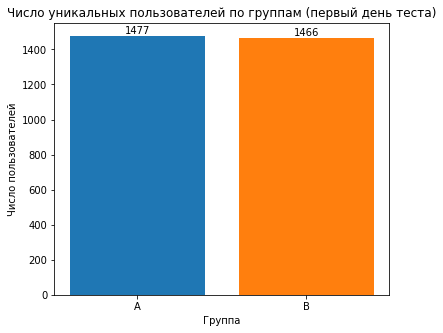

In [13]:
users_by_group = sessions_test_part.groupby('test_group')['user_id'].nunique()
print(users_by_group)

a, b = users_by_group['A'], users_by_group['B']
p_diff = 100 * abs(a - b) / a
print(f'Разница в числе пользователей между группами A и B: {p_diff:.2f}%')

fig, ax = plt.subplots(figsize=(6, 5))
ax.bar(users_by_group.index, users_by_group.values, color=['tab:blue', 'tab:orange'])
ax.set_title('Число уникальных пользователей по группам (первый день теста)')
ax.set_xlabel('Группа')
ax.set_ylabel('Число пользователей')
for i, v in enumerate(users_by_group.values):
    ax.text(i, v, str(v), ha='center', va='bottom')
plt.show()

В первый день теста в группе A было 1477 пользователей, в группе B 1466. Разница между группами составляет 0,74%, то есть группы практически равны по размеру, а такое расхождение укладывается в случайные колебания при разбиении.

#### 3.2. Проверка пересечений пользователей

In [14]:
users_a = set(sessions_test_part.loc[sessions_test_part['test_group'] == 'A', 'user_id'])
users_b = set(sessions_test_part.loc[sessions_test_part['test_group'] == 'B', 'user_id'])
intersection = users_a & users_b
print('Пользователей, попавших в обе группы:', len(intersection))

Пользователей, попавших в обе группы: 0


Пересечений нет: ни один пользователь не попал одновременно в группы A и B (0 пользователей). Выборки независимы.

#### 3.3. Равномерность разделения пользователей по устройствам

test_group       A       B
device                    
Android     0.4441  0.4557
Mac         0.1056  0.1010
PC          0.2498  0.2599
iPhone      0.2004  0.1835


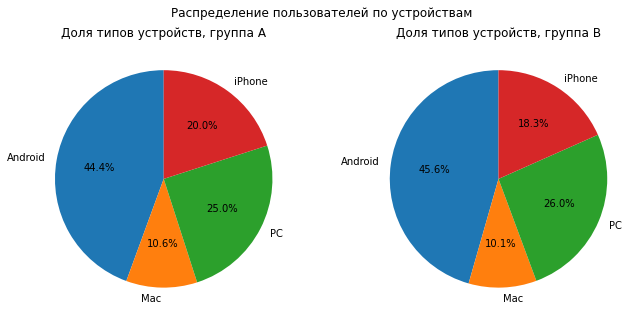

In [15]:
device_share = (
    sessions_test_part.drop_duplicates(['user_id', 'test_group'])
    .groupby('test_group')['device']
    .value_counts(normalize=True)
    .unstack(0)
)
print(device_share.round(4))

fig, axes = plt.subplots(1, 2, figsize=(11, 5))
for ax, group in zip(axes, ['A', 'B']):
    ax.pie(device_share[group], labels=device_share.index, autopct='%1.1f%%', startangle=90)
    ax.set_title(f'Доля типов устройств, группа {group}')
plt.suptitle('Распределение пользователей по устройствам')
plt.show()

Распределение по устройствам в группах A и B очень похоже. Доли в группах A/B: Android 44,4%/45,6%, PC 25,0%/26,0%, iPhone 20,0%/18,4%, Mac 10,6%/10,1%. Порядок устройств по популярности одинаков, максимальное расхождение около 1,7 п.п. (iPhone). Значимого перекоса нет.

#### 3.4. Равномерность распределения пользователей по регионам

test_group       A      B
region                   
CIS         0.4360  0.440
EU          0.1517  0.148
MENA        0.4123  0.412


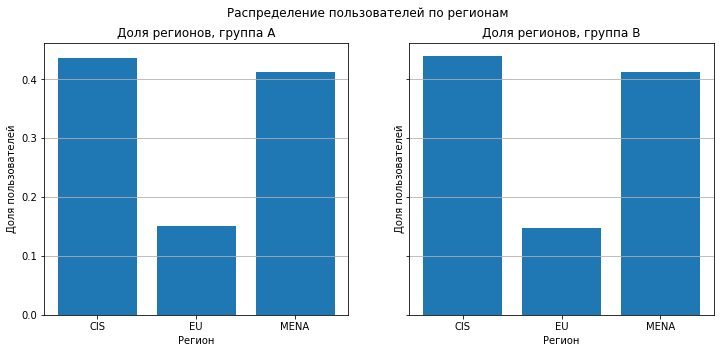

In [16]:
region_share = (
    sessions_test_part.drop_duplicates(['user_id', 'test_group'])
    .groupby('test_group')['region']
    .value_counts(normalize=True)
    .unstack(0)
)
print(region_share.round(4))

fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)
for ax, group in zip(axes, ['A', 'B']):
    ax.bar(region_share.index, region_share[group])
    ax.set_title(f'Доля регионов, группа {group}')
    ax.set_xlabel('Регион')
    ax.set_ylabel('Доля пользователей')
    ax.grid(True, axis='y')
plt.suptitle('Распределение пользователей по регионам')
plt.show()

Распределение по регионам почти идентично. Доли в группах A/B: CIS 43,6%/44,0%, MENA 41,2%/41,2%, EU 15,2%/14,8%. Расхождения не превышают 0,4 п.п. Группы сбалансированы и по регионам.

#### 3.5. Вывод после проверки A/B-теста

**Вывод по проверке A/B-теста**

- **Количество пользователей в группах.** Различие минимально: в группе A  1477 пользователей, в группе B 1466, разница составила 0,74%. Группы практически равны по размеру, перекоса в разбиении не обнаружено.
- **Независимость выборок.** Пересечений пользователей между группами A и B нет (0 пользователей), выборки независимы.
- **Устройства.** Распределение по типам устройств в группах совпадает: Android, PC, iPhone и Mac занимают схожие доли, максимальное расхождение — около 1,7 п.п. (iPhone).
- **Регионы.** Распределение по регионам (CIS, MENA, EU) практически идентично, расхождения не более 0,4 п.п.
- **Заключение.** Нарушений в проведении теста не обнаружено: пользователи разделены корректно, группы равны по размеру, независимы и сбалансированы по устройствам и регионам. A/B-тест проходит корректно, его можно продолжать и анализировать результаты.

### 4. Проверка результатов A/B-теста

#### 4.1. Получение результатов теста и подсчёт основной метрики

In [17]:
sessions_test = pd.read_csv(
    '/datasets/sessions_project_test.csv',
    parse_dates=['session_date', 'session_start_ts', 'install_date']
)
sessions_test['good_session'] = (sessions_test['page_counter'] >= 4).astype(int)

first_test = sessions_test[sessions_test['session_number'] == 1]

sessions_test.head()

,user_id,session_id,session_date,session_start_ts,install_date,session_number,registration_flag,page_counter,region,device,test_group,good_session
0,6DAE3B3654DA738E,C69249E26E58F6E2,2025-10-26,2025-10-26 18:15:05,2025-10-16,3,0,3,MENA,Android,A,0
1,0A3FE5D1DD59110A,66D66D7C9F5181B7,2025-10-21,2025-10-21 17:04:53,2025-10-15,2,1,2,CIS,Android,B,0
2,2041F1D7AA740B88,50DE51D42215E74C,2025-10-23,2025-10-23 17:39:29,2025-10-19,3,0,2,MENA,Android,A,0
3,43D7585009168086,5763C0C353C22263,2025-10-24,2025-10-24 15:01:57,2025-10-18,4,0,1,CIS,iPhone,B,0
4,15AD68B14D62D88C,B1AD09F93C1053BC,2025-10-17,2025-10-17 17:34:39,2025-10-17,1,0,2,MENA,Android,B,0


In [18]:
print('Период теста:', sessions_test['session_date'].min(), '—', sessions_test['session_date'].max())
print(sessions_test.groupby('test_group')['user_id'].nunique())
overlap = set(sessions_test.loc[sessions_test['test_group'] == 'A', 'user_id']) & \
          set(sessions_test.loc[sessions_test['test_group'] == 'B', 'user_id'])
print('Пересечение пользователей групп:', len(overlap))

Период теста: 2025-10-14 00:00:00 — 2025-11-02 00:00:00
test_group
A    15163
B    15416
Name: user_id, dtype: int64
Пересечение пользователей групп: 0


Повторная проверка на полных данных: тест шёл с 2025-10-14 по 2025-11-02 (20 дней), в группе A 15163 пользователя, в группе B 15416 (разница около 1,7%, то есть небольшая). Пересечений между группами по-прежнему нет (0). Таким образом, независимость выборок и равенство их размеров сохраняются на протяжении всего эксперимента. Каждая группа заметно больше расчётных 3761 пользователя.

#### 4.2 Формулировка нулевой и альтернативной гипотез. Определение целевой, прокси- и барьерных метрик

**Целевая метрика.** Доля успешных первых сессий — доля первых сессий пользователя, в которых просмотрено 4 и более страниц. Именно её, по мнению продуктовой команды, отражает интерес пользователей к контенту, то есть качество рекомендаций, поэтому новый алгоритм должен её повысить.

**Гипотезы** (α = 0,05, тест односторонний):

- **H₀ (нулевая):** новый алгоритм рекомендаций не увеличивает долю успешных первых сессий: доля в группе B не выше, чем в группе A (p_B ≤ p_A).
- **H₁ (альтернативная):** новый алгоритм увеличивает долю успешных первых сессий: доля в группе B выше, чем в группе A (p_B > p_A).

**Прокси-метрики** (быстрее реагируют на изменения и подсказывают, что происходит с вовлечённостью):

- среднее число просмотренных страниц за сессию;
- доля пользователей, вернувшихся в приложение на следующий день (retention 1-го дня) и на 7-й день;
- среднее число сессий на пользователя.

**Барьерные метрики** (не должны ухудшиться, иначе внедрять нельзя даже при росте целевой метрики):

- конверсия в регистрацию и конверсия в платную подписку (влияют на выручку);
- доход от рекламы на пользователя (для пользователей без подписки);
- доля быстрых «отказов» сессий с 1 страницей;
- техническое качество: время загрузки ленты, число сбоев и жалоб на приложение.

#### 4.3. Сравнение доли успешных первых сессий

In [19]:
first_test = sessions_test[sessions_test['session_number'] == 1]

summary = first_test.groupby('test_group')['good_session'].agg(['sum', 'count', 'mean'])
summary.columns = ['good_first_sessions', 'first_sessions', 'good_share']
print(summary)

p_a = summary.loc['A', 'good_share']
p_b = summary.loc['B', 'good_share']
print(f'Доля успешных первых сессий: A = {p_a:.4f}, B = {p_b:.4f}')
print(f'Разница (B - A): {p_b - p_a:.4f} ({(p_b - p_a) / p_a * 100:.2f}% относительно A)')

            good_first_sessions  first_sessions  good_share
test_group                                                 
A                          4787           15162    0.315724
B                          4851           15416    0.314673
Доля успешных первых сессий: A = 0.3157, B = 0.3147
Разница (B - A): -0.0011 (-0.33% относительно A)


Доля успешных первых сессий (4 и более страниц) в группе A составила **31,57%** (4787 из 15162), в группе B 31,47% (4851 из 15416). Разница (B−A) равна −0,11 п.п. (−0,33% относительно A), то есть значения почти совпадают, причём в тестовой группе показатель даже чуть ниже, а не выше. Это ожидаемо близко к историческому уровню (31%). Целевая динамика (рост на 3 п.п.) не наблюдается.

#### 4.4. Насколько статистически значимо изменение ключевой метрики

In [20]:
from statsmodels.stats.proportion import proportions_ztest

alpha = 0.05
count = [summary.loc['B', 'good_first_sessions'], summary.loc['A', 'good_first_sessions']]
nobs = [summary.loc['B', 'first_sessions'], summary.loc['A', 'first_sessions']]

z_stat, p_value = proportions_ztest(count, nobs, alternative='larger')
print(f'z = {z_stat:.4f}, p-value = {p_value:.4f}')

if p_value < alpha:
    print('Отвергаем H0: доля успешных первых сессий в группе B статистически значимо выше.')
else:
    print('Нет оснований отвергнуть H0: статистически значимого роста доли успешных первых сессий не выявлено.')

z = -0.1977, p-value = 0.5784
Нет оснований отвергнуть H0: статистически значимого роста доли успешных первых сессий не выявлено.


Использован z-тест для двух пропорций (односторонний: проверяем, что доля в B больше, чем в A). Получено z = −0,198 и p-value = 0,578, что заметно больше уровня значимости 0,05. Нулевую гипотезу отвергнуть нельзя: статистически значимого роста доли успешных первых сессий в группе B нет. Отрицательный знак z отражает то, что в B доля чуть ниже, но эта разница тоже статистически не значима.

#### 4.5. Вывод по результатам A/B-эксперимента

**Вывод по результатам A/B-эксперимента**

**1. Характеристики эксперимента**

- *EDA.* В историческом периоде доля успешных первых сессий (4 и более страниц) стабильна: в среднем 31,1% при колебаниях 30–33% и без тренда. Это базовый уровень целевой метрики (в расчёте использовано 0,3).
- *Планирование.* При α = 0,05, мощности 0,8 и относительном MDE 3% (рост с 0,300 до 0,309) нужно 41040 пользователей на группу, около 82 080 на оба варианта. При среднем трафике около 9 900 пользователей в день расчётная длительность составляет 9 дней (по формуле; на практике лучше проводить целыми неделями).
- *Проведение.* Тест шёл с 14 октября по 2 ноября 2025 года (20 дней). В нём участвовали 30579 пользователей: 15 163 в контрольной группе A (старый алгоритм) и 15 416 в тестовой группе B (новый алгоритм).
- *Корректность.* Разница размеров групп небольшая (0,74% в первый день, около 1,7% за весь тест, меньше порога 5%), SRM не обнаружен. Пользователи не пересекаются между группами, распределения по устройствам и регионам совпадают. Тест проведён технически корректно.

**2. Влияние на ключевую метрику**

Доля успешных первых сессий составила 31,57% в группе A и 31,47% в группе B. Разница равна −0,11 п.п., то есть −0,33% относительно A, что примерно в 9 раз меньше целевого MDE в 3%, причём с противоположным знаком. Роста ключевой метрики нет.

**3. Статистическая значимость**

p-value = 0,578 (односторонний z-тест пропорций), что значительно больше уровня значимости 0,05. Нулевую гипотезу отвергнуть нельзя: статистически значимого роста доли успешных первых сессий в группе B не обнаружено.

**4. Ограничения теста**

- *Фактическая выборка меньше расчётной.* В группах оказалось около 15 тыс. пользователей против расчётных 41040, то есть около 37% от плана. Причина в том, что метрика считается только по первым сессиям, то есть по новым пользователям, а их приток в тесте составил около 1,5 тыс. в сутки, существенно меньше средней дневной аудитории (9 900), на которую опирался расчёт длительности. При таком притоке набрать плановую выборку можно было бы примерно за 54 дня.
- *Мощность и детектируемый эффект.* Достигнутая мощность для целевого MDE 3% составляет около 40% вместо планируемых 80%. С такой выборкой тест надёжно обнаруживает лишь рост около +1,5 п.п. (примерно +4,7% относительно A), поэтому небольшой положительный эффект мог остаться незамеченным.
- *Отсутствие значимости не означает отсутствия эффекта.* Результат говорит лишь о том, что данных недостаточно, чтобы подтвердить рост. 95% доверительный интервал разницы (B − A) составляет примерно от −1,15 до +0,94 п.п. Верхняя граница (около +3% относительно A) практически совпадает с целевым MDE, то есть эффект планового размера и больше тест фактически исключает, но малый положительный эффект исключить нельзя.
- *Нет прокси и барьерных метрик* (retention, глубина просмотра, конверсии в регистрацию и подписку, доход), поэтому влияние алгоритма на них неизвестно.

**5. Рекомендация**

Внедрять новый алгоритм на основании этого теста не стоит: он не улучшил целевую метрику, а ожидаемого роста минимум на 3% точно не показал. Если команда считает, что алгоритм может давать небольшой эффект, его стоит доработать и провести повторный тест с корректно рассчитанной выборкой (не менее 41040 пользователей на группу) и с отслеживанием прокси и барьерных метрик. Заранее нужно учесть приток новых пользователей и закладывать длительность исходя из него, а не из общей дневной аудитории.